In [1]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import category_encoders as ce


In [2]:
df = pd.read_csv("../Data/term-deposit-marketing-2020.csv")
df_seg = df.copy()

In [3]:
df_seg.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,no


In [4]:
df_seg.shape

(40000, 14)

# Clean data for clustering 

In [4]:
df_seg = df_seg.drop(["month","day","contact","duration","campaign",],axis =1)

In [5]:
df_seg.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'y'],
      dtype='object')

In [45]:
df_seg.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39765 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        39765 non-null  int64  
 1   job        39765 non-null  float64
 2   marital    39765 non-null  int64  
 3   education  39765 non-null  int64  
 4   default    39765 non-null  int64  
 5   balance    39765 non-null  int64  
 6   housing    39765 non-null  int64  
 7   loan       39765 non-null  int64  
 8   y          39765 non-null  int64  
dtypes: float64(1), int64(8)
memory usage: 3.0 MB


In [7]:
def nominal_vars(df_seg):
    df_seg['default'] = df_seg['default'].map({'yes': 1, 'no': 0})
    df_seg['y'] = df_seg['y'].map({'no':0,'yes':1})
    df_seg['housing'] = df_seg['housing'].map({'yes': 1, 'no': 0})
    df_seg['loan'] = df_seg['loan'].map({'yes': 1, 'no': 0})
    df_seg["education"] = df_seg["education"].replace("unknown", np.nan)
    df_seg["job"] = df_seg["job"].replace("unknown", np.nan)
    df_seg['job'] = df_seg['job'].map({'management':0,'technician':1,'entrepreneur':2, 'blue-collar':3,
                'retired': 4, 'admin': 5,  'services': 6, 'self-employed': 7,
                'unemployed': 8,  'housemaid': 9, 'student': 10 })
    
    df_seg['marital'] = df_seg['marital'].map({'single':0,'married':1,'divorced':2})
    return df_seg

In [8]:
nominal_vars(df_seg)

,age,job,marital,education,default,balance,housing,loan,y
0,58,0.0,1,tertiary,0,2143,1,0,0
1,44,1.0,0,secondary,0,29,1,0,0
2,33,2.0,1,secondary,0,2,1,1,0
3,47,3.0,1,NaN,0,1506,1,0,0
4,33,NaN,0,NaN,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
39995,53,1.0,1,tertiary,0,395,0,0,0
39996,30,0.0,0,tertiary,0,3340,0,0,1
39997,54,5.0,2,secondary,0,200,0,0,1
39998,34,0.0,1,tertiary,0,1047,0,0,0


In [9]:
def ordinal_vars(df_seg):
    education_encoder= ce.OrdinalEncoder(cols=['education'],return_df=True,
                            mapping=[{'col':'education',
    'mapping':{'primary': 0,'secondary': 1,'tertiary': 2}}])
    df_seg[['education']] = education_encoder.fit_transform(df_seg[['education']]).astype('int')
        #[[]] used to indicate dataframe not series
    return df_seg

In [10]:
ordinal_vars(df_seg)

,age,job,marital,education,default,balance,housing,loan,y
0,58,0.0,1,2,0,2143,1,0,0
1,44,1.0,0,1,0,29,1,0,0
2,33,2.0,1,1,0,2,1,1,0
3,47,3.0,1,-1,0,1506,1,0,0
4,33,NaN,0,-1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...
39995,53,1.0,1,2,0,395,0,0,0
39996,30,0.0,0,2,0,3340,0,0,1
39997,54,5.0,2,1,0,200,0,0,1
39998,34,0.0,1,2,0,1047,0,0,0


In [11]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
y            0
dtype: int64

In [12]:
df_seg = df_seg.dropna(subset=["job"])

In [13]:
df_seg.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
y            0
dtype: int64

# Select those who actually subscribed

In [18]:
subscribed = df_seg[df_seg["y"]==1]

In [19]:
subscribed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2879 entries, 83 to 39997
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        2879 non-null   int64  
 1   job        2879 non-null   float64
 2   marital    2879 non-null   int64  
 3   education  2879 non-null   int64  
 4   default    2879 non-null   int64  
 5   balance    2879 non-null   int64  
 6   housing    2879 non-null   int64  
 7   loan       2879 non-null   int64  
 8   y          2879 non-null   int64  
dtypes: float64(1), int64(8)
memory usage: 224.9 KB


In [23]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [22]:
subscribed = subscribed.drop("y",axis =1)

In [24]:
scaler = StandardScaler()
scaled_sub_data = scaler.fit_transform(subscribed)

In [32]:
cluster_scaled_sub_data = pd.DataFrame(scaled_sub_data, columns = subscribed.columns)

In [33]:
cluster_scaled_sub_data

,age,job,marital,education,default,balance,housing,loan
0,1.748897,0.689506,0.330094,-0.231548,-0.131585,0.263773,0.984490,-0.388767
1,1.475524,0.689506,0.330094,-0.231548,-0.131585,-0.529368,-1.015755,-0.388767
2,0.108659,-0.759199,0.330094,-0.231548,-0.131585,-0.106567,0.984490,-0.388767
3,1.384400,1.051682,0.330094,-0.231548,-0.131585,0.309677,0.984490,-0.388767
4,1.293275,0.689506,0.330094,1.093756,-0.131585,-0.481393,-1.015755,-0.388767
...,...,...,...,...,...,...,...,...
2874,-0.984833,-1.121375,-1.173608,1.093756,-0.131585,-0.325043,0.984490,-0.388767
2875,1.384400,-1.121375,1.833796,1.093756,-0.131585,0.277578,-1.015755,-0.388767
2876,-1.258206,-0.759199,-1.173608,-0.231548,-0.131585,-0.120027,0.984490,-0.388767
2877,-0.893708,-1.121375,-1.173608,1.093756,-0.131585,0.607881,-1.015755,-0.388767


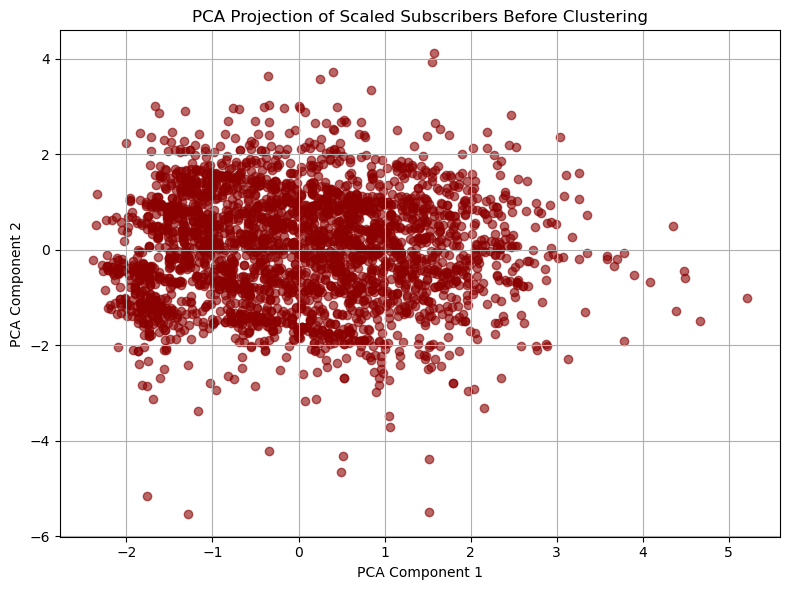

Explained variance ratio (2 components after scaling):
[0.19345744 0.17130918]
Total variance captured after scaling: 36.48%


In [34]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

seed = 23
pca_scaled = PCA(n_components=2, random_state=seed)
X_pca_2D_scaled = pca_scaled.fit_transform(cluster_scaled_sub_data)

# Plot the 2D projection of the scaled data
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca_2D_scaled[:, 0],
    X_pca_2D_scaled[:, 1],
    alpha=0.6,
    color="darkred",
)
plt.title("PCA Projection of Scaled Subscribers Before Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Explained variance ratio (2 components after scaling):")
print(pca_scaled.explained_variance_ratio_)
print(f"Total variance captured after scaling: {pca_scaled.explained_variance_ratio_.sum():.2%}")

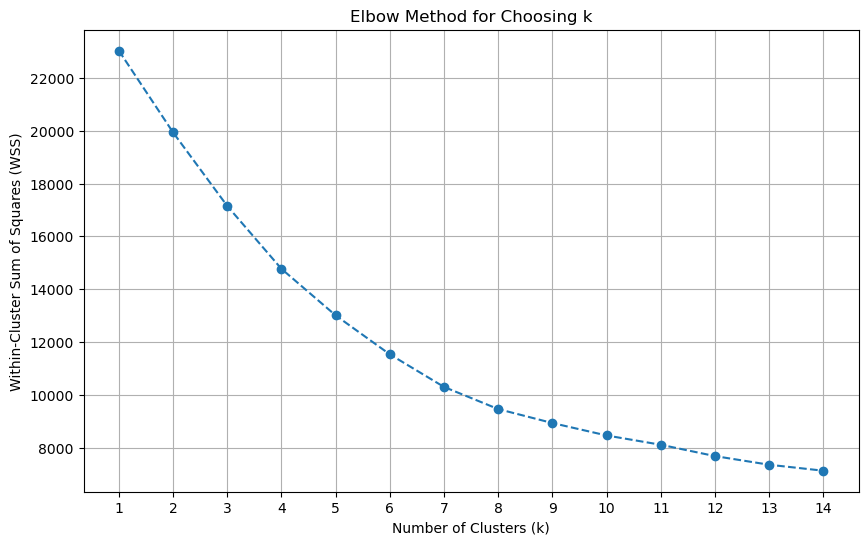

In [35]:
from sklearn.cluster import KMeans

seed = 23
k_values = range(1, 15)

wss = [
    KMeans(
        n_clusters=k,
        init="k-means++",
        max_iter=300,
        n_init=10,
        random_state=seed,
    ).fit(cluster_scaled_sub_data).inertia_
    for k in k_values
]

plt.figure(figsize=(10, 6))
plt.plot(k_values, wss, marker="o", linestyle="--")
plt.title("Elbow Method for Choosing k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WSS)")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [41]:
kmeans = KMeans(
    n_clusters=7,
    init="k-means++",
    max_iter=300,
    n_init=10,
    random_state=23,
)

data_subscribed = subscribed.copy()
data_subscribed["Cluster"] = kmeans.fit_predict(cluster_scaled_sub_data)

data_subscribed.head()

,age,job,marital,education,default,balance,housing,loan,Cluster
83,59,5.0,1,1,0,2343,1,0,5
86,56,5.0,1,1,0,45,0,0,2
87,41,1.0,1,1,0,1270,1,0,5
129,55,6.0,1,1,0,2476,1,0,5
168,54,5.0,1,2,0,184,0,0,2


In [55]:
grouped = data_subscribed.groupby("Cluster")
clusters = grouped.agg(lambda col: col.unique())
clusters[["age", "balance"]] = grouped[["age", "balance"]].mean().round(2)

clusters.T

ValueError: Must produce aggregated value

In [49]:
clusters.T

Cluster,0,1,2,3,4,5,6
age,38.747222,35.367847,52.495413,37.918367,31.016878,41.284830,40.239437
balance,719.411111,1445.509537,1658.744954,-119.571429,1021.970464,1246.704334,14610.084507
